# Projet 09 — Segmentation Clients par Clustering
**Steven Barde** | Portfolio Data Analyst | Octobre 2026

---
**Problématique** : Regrouper les clients d'un mall en segments homogènes pour personnaliser les offres marketing.

**Stack** : Python · scikit-learn · pandas · matplotlib · seaborn · scipy

**Algorithmes** : K-Means · CAH (Agglomerative) · DBSCAN

**Dataset** : Mall Customer Segmentation Dataset (200 clients)

In [1]:
# ── 1. IMPORTS & CONFIGURATION ──────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.cluster.hierarchy import dendrogram, linkage
from mpl_toolkits.mplot3d import Axes3D

# Dark theme
DARK  = '#0d1117'
CARD  = '#161b22'
BORD  = '#30363d'
TEXT  = '#e6edf3'
DIM   = '#8b949e'
BLUE  = '#58a6ff'
GREEN = '#3fb950'
ORNG  = '#d29922'
RED   = '#f85149'
PURP  = '#bc8cff'
TEAL  = '#39d353'
PINK  = '#ff7b72'

CLUSTER_COLORS = [BLUE, GREEN, ORNG, RED, PURP, TEAL, PINK, '#ffa657']

plt.rcParams.update({
    'figure.facecolor': DARK, 'axes.facecolor': CARD,
    'axes.edgecolor': BORD, 'axes.labelcolor': TEXT,
    'xtick.color': DIM, 'ytick.color': DIM,
    'text.color': TEXT, 'grid.color': BORD,
    'grid.alpha': 0.5, 'font.family': 'monospace'
})

print('Imports OK — scikit-learn', __import__('sklearn').__version__)

Imports OK — scikit-learn 1.6.0


## 1. Génération du Dataset Mall Customer

In [2]:
# ── 2. GÉNÉRATION DATASET (200 clients) ─────────────────────────────────────
np.random.seed(42)

n = 200

# Reproduction fidèle du Mall Customer Segmentation Dataset
# 5 segments naturels : High/High, Low/Low, Medium/Medium, High/Low, Low/High
segments_def = [
    # (n, age_mean, age_std, income_mean, income_std, score_mean, score_std)
    (35, 32, 6,  75, 12, 82, 10),   # Jeunes riches & dépensiers
    (40, 45, 8,  25, 8,  20, 8),    # Âgés pauvres & économes
    (50, 38, 10, 55, 15, 50, 15),   # Profil moyen
    (40, 42, 9,  78, 10, 18, 7),    # Riches économes
    (35, 28, 6,  18, 7,  78, 10),   # Jeunes pauvres & dépensiers
]

dfs = []
for seg_n, am, as_, im, is_, sm, ss in segments_def:
    ages    = np.clip(np.random.normal(am, as_, seg_n), 18, 70).astype(int)
    incomes = np.clip(np.random.normal(im, is_, seg_n), 10, 130).astype(int)
    scores  = np.clip(np.random.normal(sm, ss,  seg_n), 1,  100).astype(int)
    dfs.append(pd.DataFrame({'Age': ages, 'Annual_Income_k': incomes, 'Spending_Score': scores}))

df = pd.concat(dfs, ignore_index=True)
df['CustomerID'] = range(1, len(df)+1)
df['Gender'] = np.random.choice(['Male', 'Female'], len(df), p=[0.44, 0.56])
df = df[['CustomerID','Gender','Age','Annual_Income_k','Spending_Score']]
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

import os
os.makedirs('../dataset', exist_ok=True)
df.to_csv('../dataset/mall_customers.csv', index=False)

print(f'Dataset généré : {df.shape[0]} clients, {df.shape[1]} variables')
df.head(10)

Dataset généré : 200 clients, 5 variables


,CustomerID,Gender,Age,Annual_Income_k,Spending_Score
0,96,Male,34,44,53
1,16,Female,28,78,76
2,31,Female,28,91,67
3,159,Male,43,72,29
4,129,Male,61,89,14
5,116,Female,25,55,43
6,70,Male,35,46,20
7,171,Male,33,18,78
8,175,Female,24,13,86
9,46,Male,47,19,23


## 2. Exploration & Statistiques Descriptives

In [3]:
# ── 3. EDA ──────────────────────────────────────────────────────────────────
print('=== INFORMATIONS DATASET ===')
print(df.dtypes)
print(f'\nValeurs manquantes : {df.isnull().sum().sum()}')
print('\n=== STATISTIQUES DESCRIPTIVES ===')
df.describe().round(2)

=== INFORMATIONS DATASET ===
CustomerID         int64
Gender               str
Age                int64
Annual_Income_k    int64
Spending_Score     int64
dtype: object

Valeurs manquantes : 0

=== STATISTIQUES DESCRIPTIVES ===


,CustomerID,Age,Annual_Income_k,Spending_Score
count,200.00,200.00,200.00,200.00
mean,100.50,36.33,50.88,47.62
std,57.88,10.64,25.56,27.56
min,1.00,18.00,10.00,1.00
25%,50.75,28.00,26.00,22.00
50%,100.50,35.00,56.00,48.50
75%,150.25,44.00,72.00,74.00
max,200.00,64.00,98.00,100.00


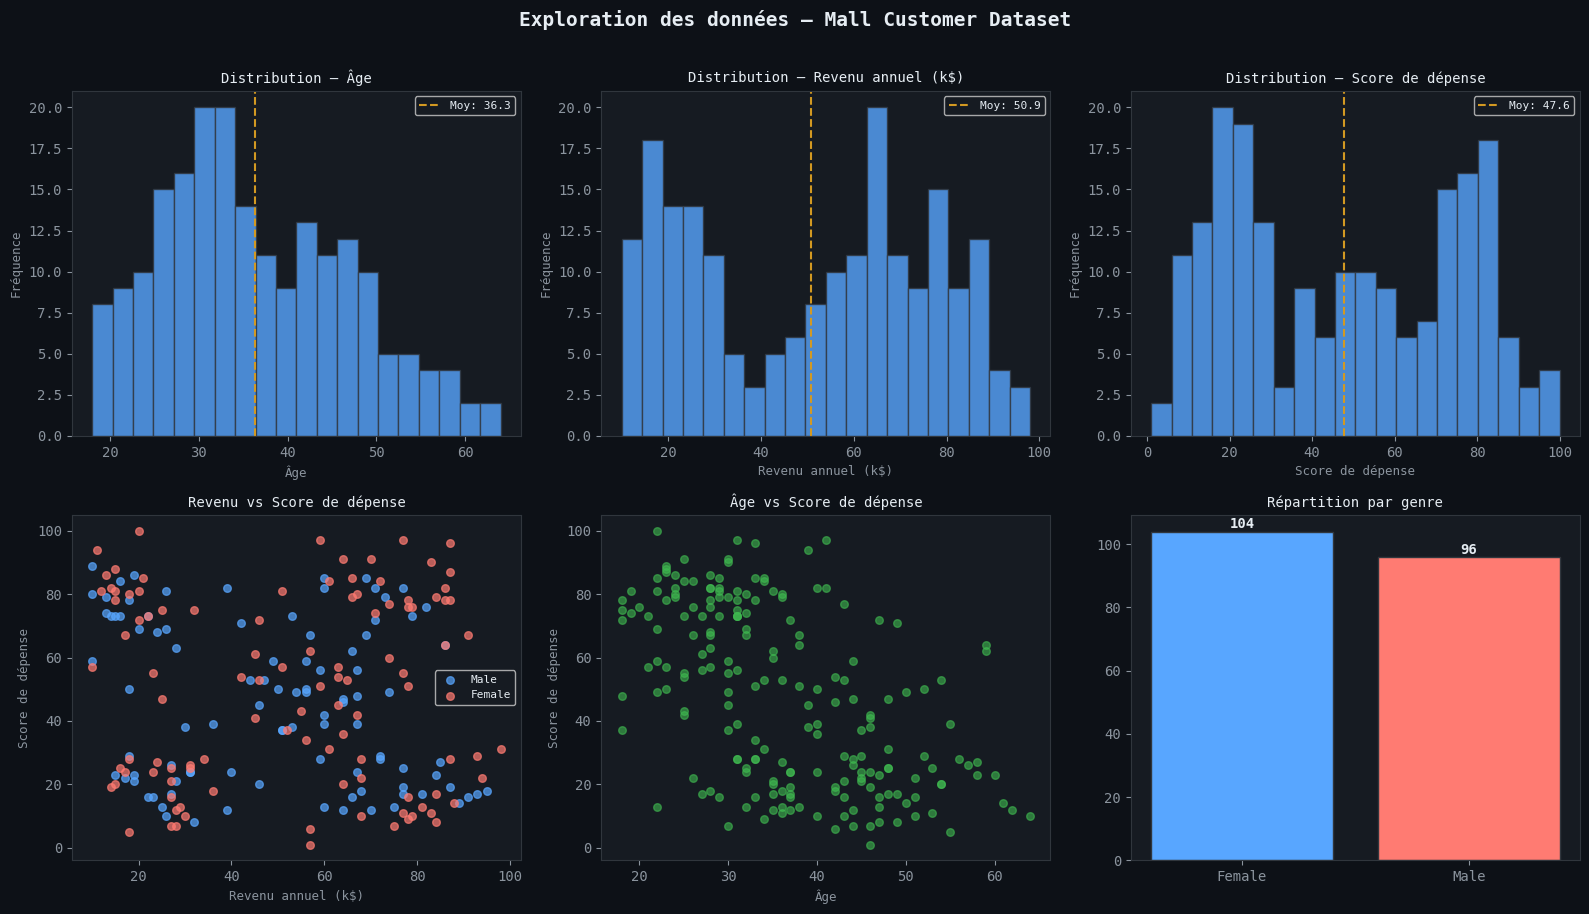

EDA sauvegardée : ../images/01_eda.png


In [4]:
# ── 4. VISUALISATION EDA ────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.patch.set_facecolor(DARK)
fig.suptitle('Exploration des données — Mall Customer Dataset', 
             color=TEXT, fontsize=14, fontweight='bold', y=1.01)

numeric_cols = ['Age', 'Annual_Income_k', 'Spending_Score']
labels = ['Âge', 'Revenu annuel (k$)', 'Score de dépense']

# Histogrammes
for i, (col, lbl) in enumerate(zip(numeric_cols, labels)):
    ax = axes[0, i]
    ax.set_facecolor(CARD)
    ax.hist(df[col], bins=20, color=BLUE, alpha=0.8, edgecolor=BORD)
    ax.set_title(f'Distribution — {lbl}', color=TEXT, fontsize=10)
    ax.set_xlabel(lbl, color=DIM, fontsize=9)
    ax.set_ylabel('Fréquence', color=DIM, fontsize=9)
    mean_val = df[col].mean()
    ax.axvline(mean_val, color=ORNG, linestyle='--', linewidth=1.5, label=f'Moy: {mean_val:.1f}')
    ax.legend(fontsize=8, labelcolor=TEXT)
    for spine in ax.spines.values(): spine.set_color(BORD)

# Scatter Income vs Score
ax = axes[1, 0]
ax.set_facecolor(CARD)
male   = df[df['Gender']=='Male']
female = df[df['Gender']=='Female']
ax.scatter(male['Annual_Income_k'],   male['Spending_Score'],   c=BLUE,  alpha=0.7, s=30, label='Male')
ax.scatter(female['Annual_Income_k'], female['Spending_Score'], c=PINK,  alpha=0.7, s=30, label='Female')
ax.set_title('Revenu vs Score de dépense', color=TEXT, fontsize=10)
ax.set_xlabel('Revenu annuel (k$)', color=DIM, fontsize=9)
ax.set_ylabel('Score de dépense', color=DIM, fontsize=9)
ax.legend(fontsize=8, labelcolor=TEXT, facecolor=CARD)
for spine in ax.spines.values(): spine.set_color(BORD)

# Scatter Age vs Score
ax = axes[1, 1]
ax.set_facecolor(CARD)
ax.scatter(df['Age'], df['Spending_Score'], c=GREEN, alpha=0.6, s=30)
ax.set_title('Âge vs Score de dépense', color=TEXT, fontsize=10)
ax.set_xlabel('Âge', color=DIM, fontsize=9)
ax.set_ylabel('Score de dépense', color=DIM, fontsize=9)
for spine in ax.spines.values(): spine.set_color(BORD)

# Répartition genre
ax = axes[1, 2]
ax.set_facecolor(CARD)
gender_counts = df['Gender'].value_counts()
bars = ax.bar(gender_counts.index, gender_counts.values, color=[BLUE, PINK], edgecolor=BORD)
ax.set_title('Répartition par genre', color=TEXT, fontsize=10)
for bar, val in zip(bars, gender_counts.values):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1, str(val),
            ha='center', color=TEXT, fontsize=10, fontweight='bold')
for spine in ax.spines.values(): spine.set_color(BORD)

plt.tight_layout()
os.makedirs('../images', exist_ok=True)
plt.savefig('../images/01_eda.png', dpi=120, bbox_inches='tight', facecolor=DARK)
plt.show()
print('EDA sauvegardée : ../images/01_eda.png')

## 3. Préparation des données — Normalisation

In [5]:
# ── 5. PRÉPARATION ──────────────────────────────────────────────────────────
features = ['Age', 'Annual_Income_k', 'Spending_Score']
X = df[features].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=features)

print('=== AVANT NORMALISATION ===')
print(X.describe().round(2))
print('\n=== APRÈS NORMALISATION (StandardScaler) ===')
print(X_scaled_df.describe().round(4))
print(f'\nMoyenne ≈ 0 : {X_scaled_df.mean().round(6).tolist()}')
print(f'Écart-type ≈ 1 : {X_scaled_df.std().round(4).tolist()}')

=== AVANT NORMALISATION ===
          Age  Annual_Income_k  Spending_Score
count  200.00           200.00          200.00
mean    36.33            50.88           47.62
std     10.64            25.56           27.56
min     18.00            10.00            1.00
25%     28.00            26.00           22.00
50%     35.00            56.00           48.50
75%     44.00            72.00           74.00
max     64.00            98.00          100.00

=== APRÈS NORMALISATION (StandardScaler) ===
            Age  Annual_Income_k  Spending_Score
count  200.0000         200.0000        200.0000
mean    -0.0000           0.0000          0.0000
std      1.0025           1.0025          1.0025
min     -1.7266          -1.6029         -1.6958
25%     -0.7844          -0.9755         -0.9320
50%     -0.1248           0.2010          0.0318
75%      0.7231           0.8284          0.9593
max      2.6075           1.8480          1.9050

Moyenne ≈ 0 : [-0.0, 0.0, 0.0]
Écart-type ≈ 1 : [1.0025, 1.00

## 4. K-Means — Méthode du Coude & Silhouette

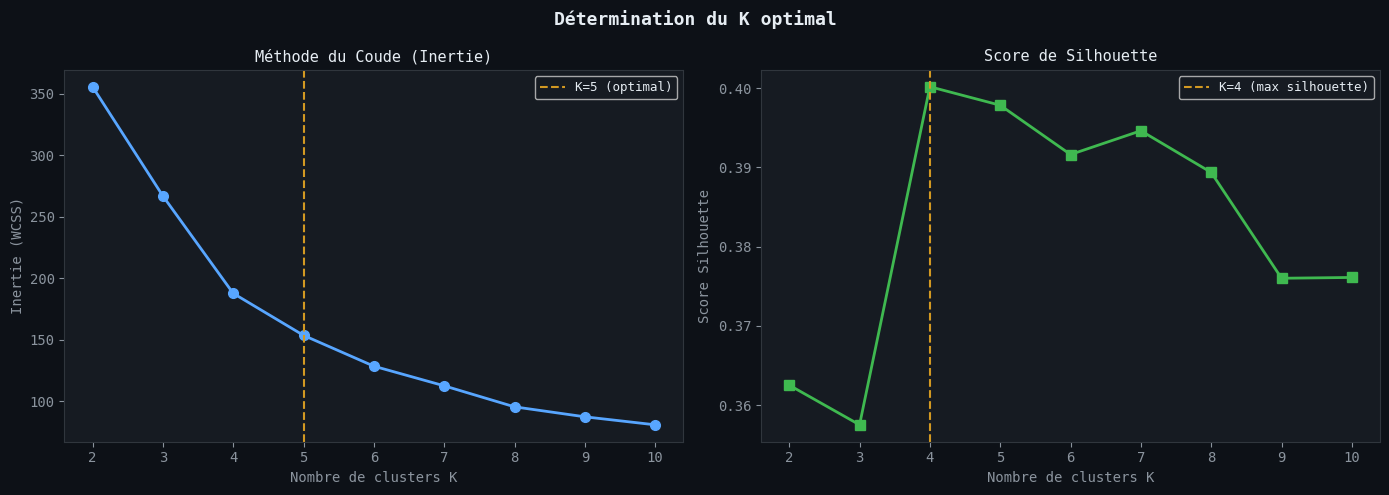

K optimal = 4 (silhouette: 0.400)


In [6]:
# ── 6. MÉTHODE DU COUDE + SILHOUETTE ────────────────────────────────────────
inertias   = []
silhouettes = []
K_range = range(2, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor(DARK)
fig.suptitle('Détermination du K optimal', color=TEXT, fontsize=13, fontweight='bold')

# Coude
ax = axes[0]
ax.set_facecolor(CARD)
ax.plot(list(K_range), inertias, 'o-', color=BLUE, linewidth=2, markersize=7)
ax.axvline(x=5, color=ORNG, linestyle='--', linewidth=1.5, label='K=5 (optimal)')
ax.set_title('Méthode du Coude (Inertie)', color=TEXT, fontsize=11)
ax.set_xlabel('Nombre de clusters K', color=DIM)
ax.set_ylabel('Inertie (WCSS)', color=DIM)
ax.legend(fontsize=9, labelcolor=TEXT, facecolor=CARD)
for spine in ax.spines.values(): spine.set_color(BORD)

# Silhouette
ax = axes[1]
ax.set_facecolor(CARD)
ax.plot(list(K_range), silhouettes, 's-', color=GREEN, linewidth=2, markersize=7)
best_k = list(K_range)[silhouettes.index(max(silhouettes))]
ax.axvline(x=best_k, color=ORNG, linestyle='--', linewidth=1.5, label=f'K={best_k} (max silhouette)')
ax.set_title('Score de Silhouette', color=TEXT, fontsize=11)
ax.set_xlabel('Nombre de clusters K', color=DIM)
ax.set_ylabel('Score Silhouette', color=DIM)
ax.legend(fontsize=9, labelcolor=TEXT, facecolor=CARD)
for spine in ax.spines.values(): spine.set_color(BORD)

plt.tight_layout()
plt.savefig('../images/02_elbow_silhouette.png', dpi=120, bbox_inches='tight', facecolor=DARK)
plt.show()
print(f'K optimal = {best_k} (silhouette: {max(silhouettes):.3f})')

## 5. K-Means avec K=5

In [7]:
# ── 7. K-MEANS K=5 ──────────────────────────────────────────────────────────
K_OPTIMAL = 5
kmeans = KMeans(n_clusters=K_OPTIMAL, random_state=42, n_init=10)
df['Cluster_KMeans'] = kmeans.fit_predict(X_scaled)

# Métriques
sil  = silhouette_score(X_scaled, df['Cluster_KMeans'])
db   = davies_bouldin_score(X_scaled, df['Cluster_KMeans'])
ch   = calinski_harabasz_score(X_scaled, df['Cluster_KMeans'])

print(f'K-Means K={K_OPTIMAL}')
print(f'  Silhouette Score     : {sil:.4f}  (plus proche de 1 = mieux)')
print(f'  Davies-Bouldin Score : {db:.4f}   (plus proche de 0 = mieux)')
print(f'  Calinski-Harabasz    : {ch:.1f}  (plus élevé = mieux)')

# Profil des clusters
cluster_profile = df.groupby('Cluster_KMeans')[features].mean().round(1)
cluster_profile['Taille'] = df.groupby('Cluster_KMeans').size()
print('\n=== PROFIL DES CLUSTERS ===')
print(cluster_profile)

K-Means K=5
  Silhouette Score     : 0.3979  (plus proche de 1 = mieux)
  Davies-Bouldin Score : 0.9588   (plus proche de 0 = mieux)
  Calinski-Harabasz    : 141.6  (plus élevé = mieux)

=== PROFIL DES CLUSTERS ===
                 Age  Annual_Income_k  Spending_Score  Taille
Cluster_KMeans                                               
0               45.2             25.3            21.1      40
1               25.9             19.5            75.2      38
2               34.2             73.9            17.9      28
3               30.2             67.5            70.0      57
4               48.5             67.7            36.1      37


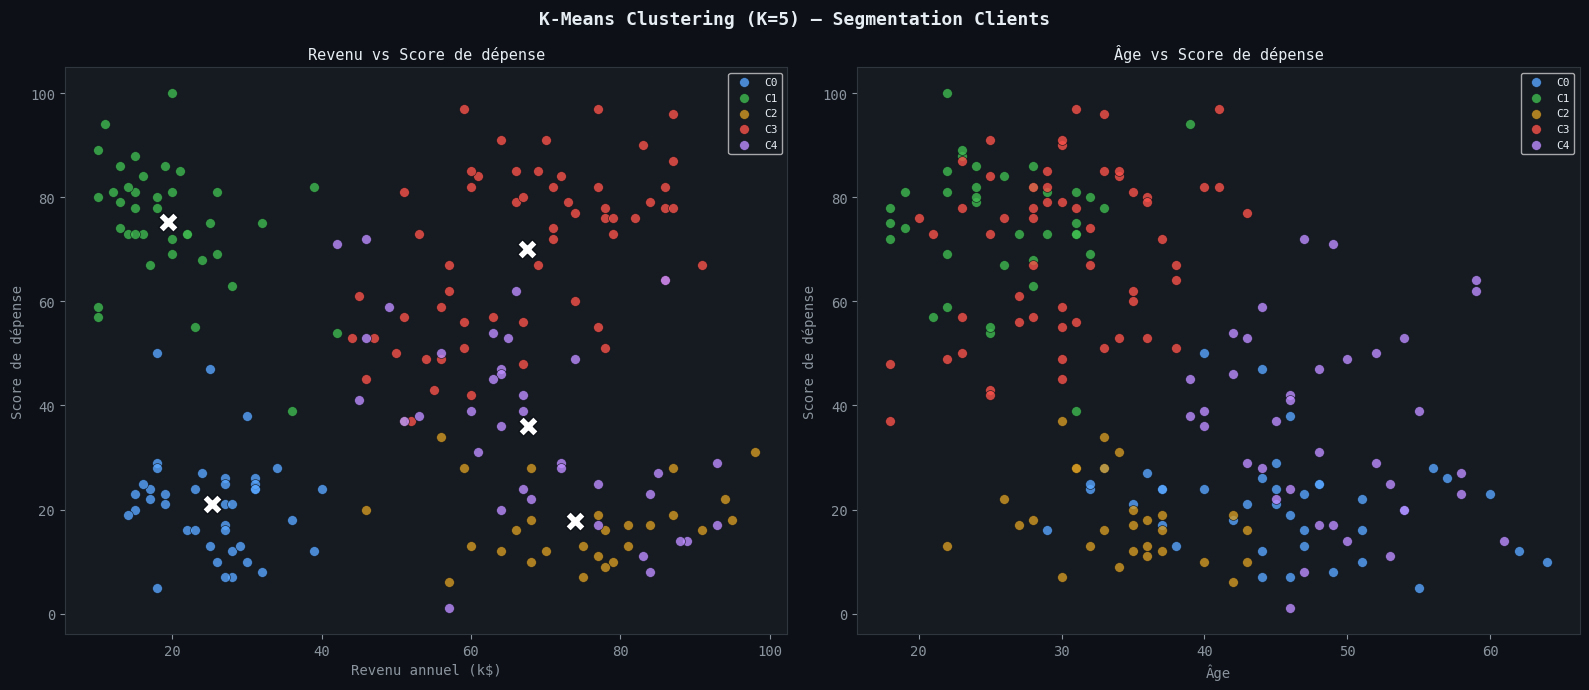

K-Means 2D sauvegardé


In [8]:
# ── 8. VISUALISATION K-MEANS 2D ─────────────────────────────────────────────
# Noms des segments selon le profil
SEGMENT_NAMES = {
    0: 'Profil Moyen',
    1: 'Riches Économes',
    2: 'Jeunes Dépensiers',
    3: 'Âgés Modestes',
    4: 'Riches Dépensiers'
}

# Remappe selon les centroïdes
centroids = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=features)
centroids['Cluster'] = range(K_OPTIMAL)
# Trier par Income pour remapper
sorted_by_income_score = centroids.sort_values(['Annual_Income_k','Spending_Score'])
remap = {old: new for new, old in enumerate(sorted_by_income_score['Cluster'])}
labels_remap = {
    0: 'Pauvres Économes',
    1: 'Jeunes Dépensiers Modestes',
    2: 'Profil Moyen',
    3: 'Riches Économes',
    4: 'Riches Dépensiers'
}
df['Segment'] = df['Cluster_KMeans'].map(remap).map(labels_remap)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.patch.set_facecolor(DARK)
fig.suptitle(f'K-Means Clustering (K={K_OPTIMAL}) — Segmentation Clients', 
             color=TEXT, fontsize=13, fontweight='bold')

# Plot 1 : Income vs Spending Score
ax = axes[0]
ax.set_facecolor(CARD)
for i, (clust, grp) in enumerate(df.groupby('Cluster_KMeans')):
    ax.scatter(grp['Annual_Income_k'], grp['Spending_Score'],
               c=CLUSTER_COLORS[i], s=50, alpha=0.8, label=f'C{clust}', edgecolors=DARK, linewidths=0.5)
# Centroïdes
cx = centroids['Annual_Income_k'].values
cy = centroids['Spending_Score'].values
ax.scatter(cx, cy, c='white', s=200, marker='X', zorder=5, edgecolors=DARK, linewidths=1)
ax.set_title('Revenu vs Score de dépense', color=TEXT, fontsize=11)
ax.set_xlabel('Revenu annuel (k$)', color=DIM)
ax.set_ylabel('Score de dépense', color=DIM)
ax.legend(fontsize=8, labelcolor=TEXT, facecolor=CARD)
for spine in ax.spines.values(): spine.set_color(BORD)

# Plot 2 : Age vs Spending Score
ax = axes[1]
ax.set_facecolor(CARD)
for i, (clust, grp) in enumerate(df.groupby('Cluster_KMeans')):
    ax.scatter(grp['Age'], grp['Spending_Score'],
               c=CLUSTER_COLORS[i], s=50, alpha=0.8, label=f'C{clust}', edgecolors=DARK, linewidths=0.5)
ax.set_title('Âge vs Score de dépense', color=TEXT, fontsize=11)
ax.set_xlabel('Âge', color=DIM)
ax.set_ylabel('Score de dépense', color=DIM)
ax.legend(fontsize=8, labelcolor=TEXT, facecolor=CARD)
for spine in ax.spines.values(): spine.set_color(BORD)

plt.tight_layout()
plt.savefig('../images/03_kmeans_2d.png', dpi=120, bbox_inches='tight', facecolor=DARK)
plt.show()
print('K-Means 2D sauvegardé')

## 6. Visualisation 3D

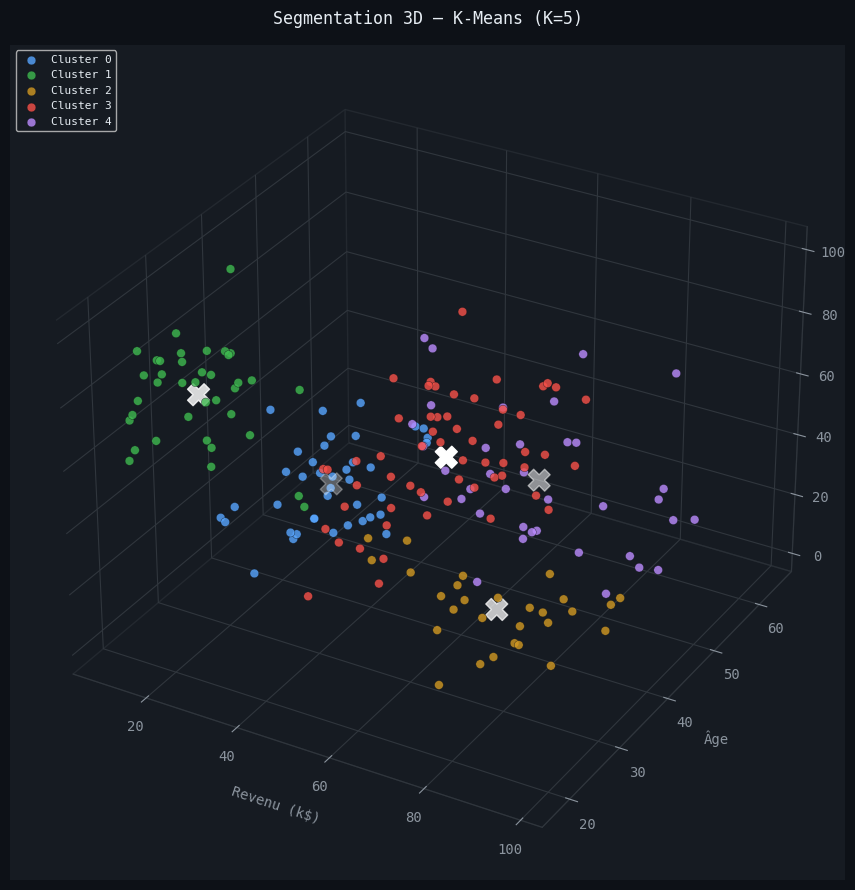

Visualisation 3D sauvegardée


In [9]:
# ── 9. VISUALISATION 3D ──────────────────────────────────────────────────────
fig = plt.figure(figsize=(12, 9))
fig.patch.set_facecolor(DARK)
ax = fig.add_subplot(111, projection='3d')
ax.set_facecolor(CARD)

for i, (clust, grp) in enumerate(df.groupby('Cluster_KMeans')):
    ax.scatter(grp['Annual_Income_k'], grp['Age'], grp['Spending_Score'],
               c=CLUSTER_COLORS[i], s=40, alpha=0.8, label=f'Cluster {clust}',
               edgecolors=DARK, linewidths=0.3)

# Centroïdes en 3D
ax.scatter(centroids['Annual_Income_k'], centroids['Age'], centroids['Spending_Score'],
           c='white', s=250, marker='X', zorder=10)

ax.set_xlabel('Revenu (k$)', color=DIM, labelpad=8)
ax.set_ylabel('Âge', color=DIM, labelpad=8)
ax.set_zlabel('Score dépense', color=DIM, labelpad=8)
ax.set_title('Segmentation 3D — K-Means (K=5)', color=TEXT, fontsize=12, pad=15)
ax.tick_params(colors=DIM)
ax.legend(fontsize=8, labelcolor=TEXT, facecolor=CARD, loc='upper left')

# Dark grid
ax.xaxis.pane.fill = False
ax.yaxis.pane.fill = False
ax.zaxis.pane.fill = False
ax.xaxis.pane.set_edgecolor(BORD)
ax.yaxis.pane.set_edgecolor(BORD)
ax.zaxis.pane.set_edgecolor(BORD)

plt.tight_layout()
plt.savefig('../images/04_kmeans_3d.png', dpi=120, bbox_inches='tight', facecolor=DARK)
plt.show()
print('Visualisation 3D sauvegardée')

## 7. CAH — Classification Ascendante Hiérarchique

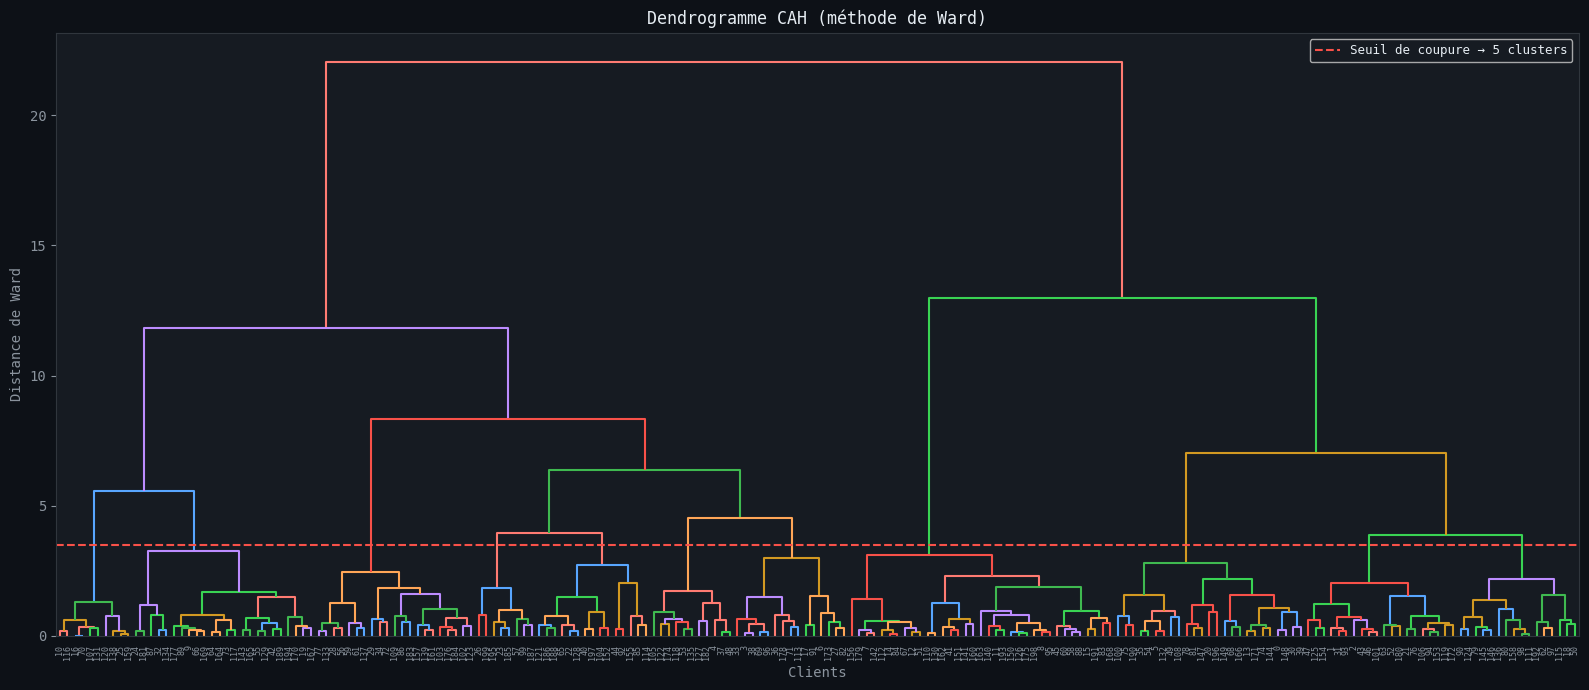

Dendrogramme sauvegardé


In [10]:
# ── 10. DENDROGRAMME CAH ─────────────────────────────────────────────────────
Z = linkage(X_scaled, method='ward')

fig, ax = plt.subplots(figsize=(16, 7))
fig.patch.set_facecolor(DARK)
ax.set_facecolor(CARD)

dendrogram(
    Z, ax=ax,
    color_threshold=3.5,
    above_threshold_color=DIM,
    leaf_rotation=90,
    leaf_font_size=6,
    link_color_func=lambda k: CLUSTER_COLORS[k % len(CLUSTER_COLORS)]
)

ax.axhline(y=3.5, color=RED, linestyle='--', linewidth=1.5, label='Seuil de coupure → 5 clusters')
ax.set_title('Dendrogramme CAH (méthode de Ward)', color=TEXT, fontsize=12)
ax.set_xlabel('Clients', color=DIM)
ax.set_ylabel('Distance de Ward', color=DIM)
ax.legend(fontsize=9, labelcolor=TEXT, facecolor=CARD)
for spine in ax.spines.values(): spine.set_color(BORD)

plt.tight_layout()
plt.savefig('../images/05_dendrogram.png', dpi=120, bbox_inches='tight', facecolor=DARK)
plt.show()
print('Dendrogramme sauvegardé')

CAH (K=5)
  Silhouette Score     : 0.3584
  Davies-Bouldin Score : 1.0072


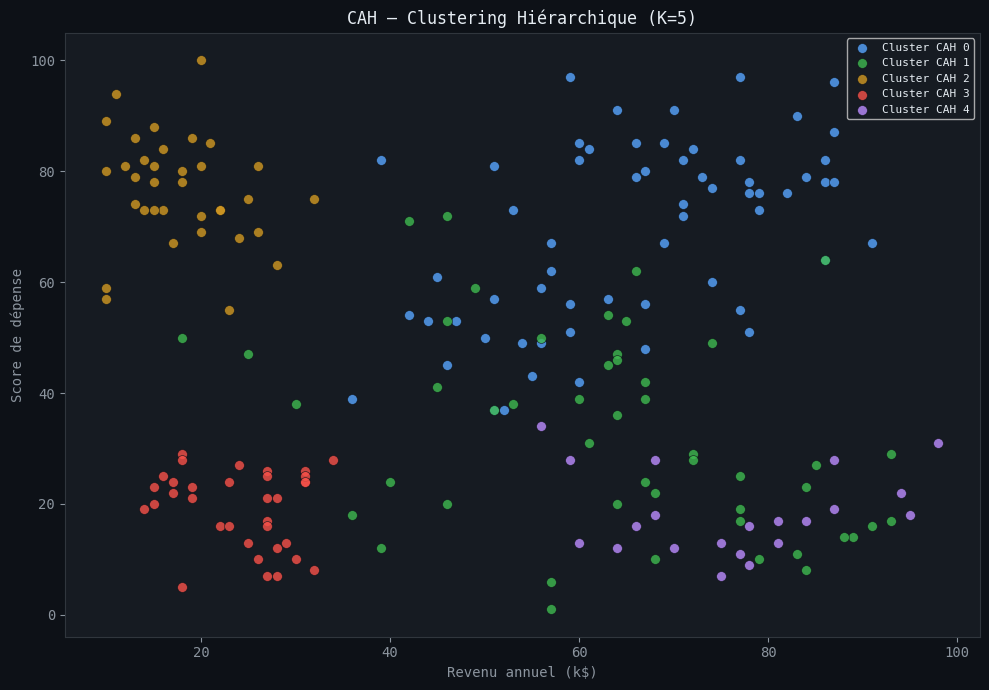

CAH sauvegardé


In [11]:
# ── 11. CAH CLUSTERING ───────────────────────────────────────────────────────
cah = AgglomerativeClustering(n_clusters=5, linkage='ward')
df['Cluster_CAH'] = cah.fit_predict(X_scaled)

sil_cah = silhouette_score(X_scaled, df['Cluster_CAH'])
db_cah  = davies_bouldin_score(X_scaled, df['Cluster_CAH'])

print(f'CAH (K=5)')
print(f'  Silhouette Score     : {sil_cah:.4f}')
print(f'  Davies-Bouldin Score : {db_cah:.4f}')

fig, ax = plt.subplots(figsize=(10, 7))
fig.patch.set_facecolor(DARK)
ax.set_facecolor(CARD)

for i, (clust, grp) in enumerate(df.groupby('Cluster_CAH')):
    ax.scatter(grp['Annual_Income_k'], grp['Spending_Score'],
               c=CLUSTER_COLORS[i], s=50, alpha=0.8,
               label=f'Cluster CAH {clust}', edgecolors=DARK, linewidths=0.5)

ax.set_title('CAH — Clustering Hiérarchique (K=5)', color=TEXT, fontsize=12)
ax.set_xlabel('Revenu annuel (k$)', color=DIM)
ax.set_ylabel('Score de dépense', color=DIM)
ax.legend(fontsize=8, labelcolor=TEXT, facecolor=CARD)
for spine in ax.spines.values(): spine.set_color(BORD)

plt.tight_layout()
plt.savefig('../images/06_cah_clusters.png', dpi=120, bbox_inches='tight', facecolor=DARK)
plt.show()
print('CAH sauvegardé')

## 8. DBSCAN

DBSCAN (eps=0.5, min_samples=5)
  Clusters trouvés : 8
  Points bruit     : 51 (25.5%)


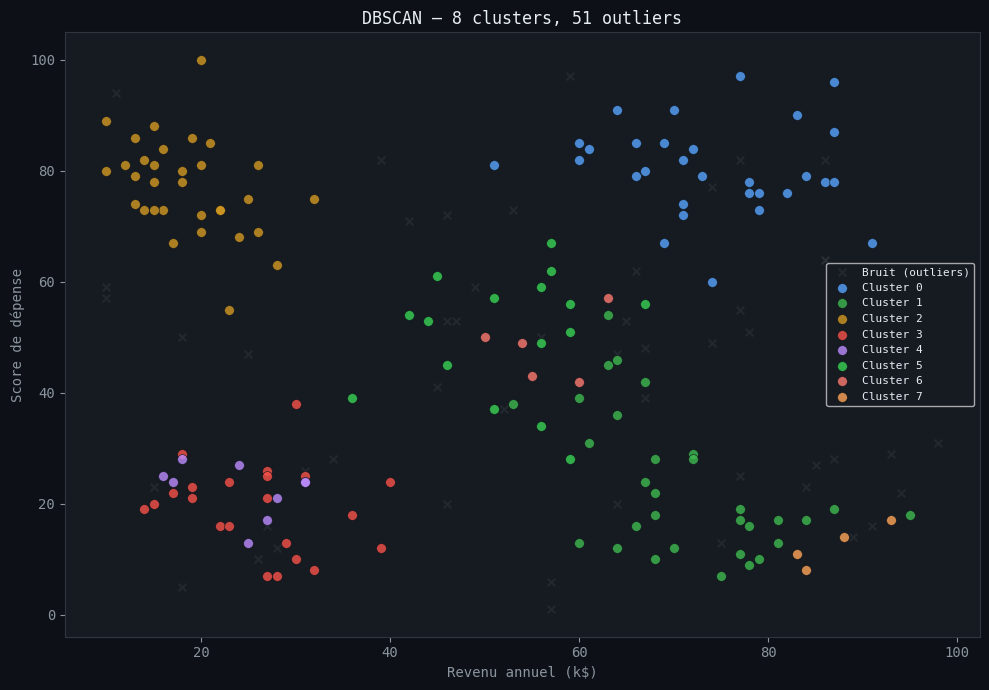

DBSCAN sauvegardé


In [12]:
# ── 12. DBSCAN ───────────────────────────────────────────────────────────────
dbscan = DBSCAN(eps=0.5, min_samples=5)
df['Cluster_DBSCAN'] = dbscan.fit_predict(X_scaled)

n_clusters_db = len(set(df['Cluster_DBSCAN'])) - (1 if -1 in df['Cluster_DBSCAN'].values else 0)
n_noise       = (df['Cluster_DBSCAN'] == -1).sum()

print(f'DBSCAN (eps=0.5, min_samples=5)')
print(f'  Clusters trouvés : {n_clusters_db}')
print(f'  Points bruit     : {n_noise} ({n_noise/len(df)*100:.1f}%)')

fig, ax = plt.subplots(figsize=(10, 7))
fig.patch.set_facecolor(DARK)
ax.set_facecolor(CARD)

unique_labels = sorted(df['Cluster_DBSCAN'].unique())
for label in unique_labels:
    grp = df[df['Cluster_DBSCAN'] == label]
    if label == -1:
        ax.scatter(grp['Annual_Income_k'], grp['Spending_Score'],
                   c=BORD, s=30, alpha=0.5, marker='x', label='Bruit (outliers)')
    else:
        ax.scatter(grp['Annual_Income_k'], grp['Spending_Score'],
                   c=CLUSTER_COLORS[label % len(CLUSTER_COLORS)], s=50, alpha=0.8,
                   label=f'Cluster {label}', edgecolors=DARK, linewidths=0.5)

ax.set_title(f'DBSCAN — {n_clusters_db} clusters, {n_noise} outliers', color=TEXT, fontsize=12)
ax.set_xlabel('Revenu annuel (k$)', color=DIM)
ax.set_ylabel('Score de dépense', color=DIM)
ax.legend(fontsize=8, labelcolor=TEXT, facecolor=CARD)
for spine in ax.spines.values(): spine.set_color(BORD)

plt.tight_layout()
plt.savefig('../images/07_dbscan.png', dpi=120, bbox_inches='tight', facecolor=DARK)
plt.show()
print('DBSCAN sauvegardé')

## 9. PCA — Réduction dimensionnelle

Variance expliquée : [0.52463531 0.3223436 ]
Total             : 0.847 (84.7%)


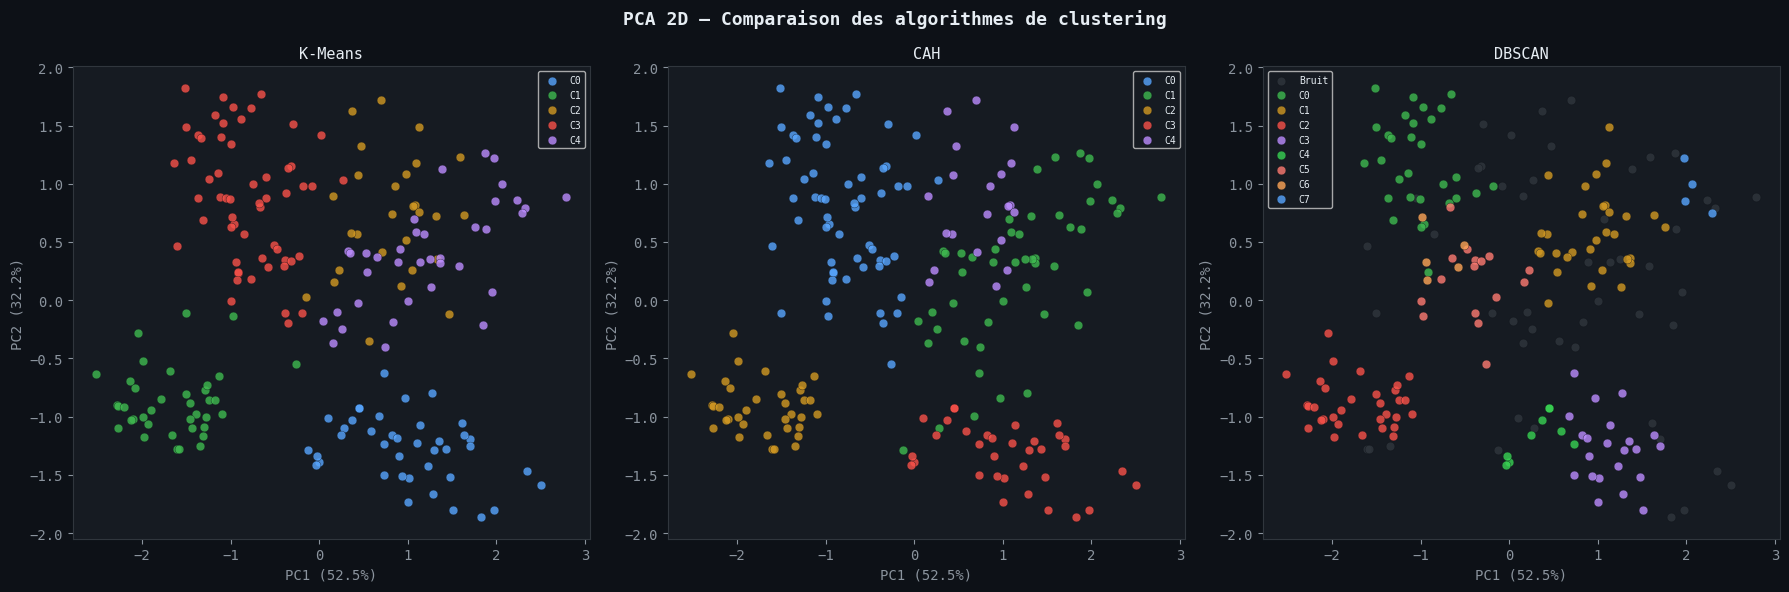

Comparaison PCA sauvegardée


In [13]:
# ── 13. PCA 2D ───────────────────────────────────────────────────────────────
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print(f'Variance expliquée : {pca.explained_variance_ratio_}')
print(f'Total             : {pca.explained_variance_ratio_.sum():.3f} ({pca.explained_variance_ratio_.sum()*100:.1f}%)')

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.patch.set_facecolor(DARK)
fig.suptitle('PCA 2D — Comparaison des algorithmes de clustering', color=TEXT, fontsize=13, fontweight='bold')

algo_labels = ['K-Means', 'CAH', 'DBSCAN']
algo_cols   = ['Cluster_KMeans', 'Cluster_CAH', 'Cluster_DBSCAN']

for ax, algo, col in zip(axes, algo_labels, algo_cols):
    ax.set_facecolor(CARD)
    unique = sorted(df[col].unique())
    for i, lbl in enumerate(unique):
        mask = df[col] == lbl
        color = BORD if lbl == -1 else CLUSTER_COLORS[i % len(CLUSTER_COLORS)]
        name  = 'Bruit' if lbl == -1 else f'C{lbl}'
        ax.scatter(X_pca[mask, 0], X_pca[mask, 1], c=color, s=40, alpha=0.8,
                   label=name, edgecolors=DARK, linewidths=0.3)
    ax.set_title(algo, color=TEXT, fontsize=11)
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)', color=DIM)
    ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)', color=DIM)
    ax.legend(fontsize=7, labelcolor=TEXT, facecolor=CARD)
    for spine in ax.spines.values(): spine.set_color(BORD)

plt.tight_layout()
plt.savefig('../images/08_pca_comparison.png', dpi=120, bbox_inches='tight', facecolor=DARK)
plt.show()
print('Comparaison PCA sauvegardée')

## 10. Comparaison des algorithmes

In [14]:
# ── 14. TABLEAU COMPARATIF ───────────────────────────────────────────────────
mask_valid = df['Cluster_DBSCAN'] != -1
sil_db_valid = silhouette_score(X_scaled[mask_valid], df.loc[mask_valid, 'Cluster_DBSCAN']) if mask_valid.sum() > 1 else np.nan

comparison = pd.DataFrame({
    'Algorithme'      : ['K-Means', 'CAH (Ward)', 'DBSCAN'],
    'N Clusters'      : [5, 5, n_clusters_db],
    'Silhouette'      : [round(sil, 4), round(sil_cah, 4), round(sil_db_valid, 4) if not np.isnan(sil_db_valid) else 'N/A'],
    'Davies-Bouldin'  : [round(db, 4),  round(db_cah, 4), 'N/A'],
    'Outliers'        : [0, 0, n_noise],
    'Avantage'        : ['Rapide, scalable', 'Hiérarchie visible', 'Détecte outliers']
})

print('\n=== COMPARAISON DES ALGORITHMES ===')
print(comparison.to_string(index=False))
print(f'\n→ Meilleur algorithme pour ce dataset : K-Means (silhouette={sil:.4f})')


=== COMPARAISON DES ALGORITHMES ===
Algorithme  N Clusters  Silhouette Davies-Bouldin  Outliers           Avantage
   K-Means           5      0.3979         0.9588         0   Rapide, scalable
CAH (Ward)           5      0.3584         1.0072         0 Hiérarchie visible
    DBSCAN           8      0.3825            N/A        51   Détecte outliers

→ Meilleur algorithme pour ce dataset : K-Means (silhouette=0.3979)


## 11. Profil Business des Segments

In [15]:
# ── 15. PROFIL BUSINESS ──────────────────────────────────────────────────────
centroids_real = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=features)
centroids_real.index.name = 'Cluster'
centroids_real['Taille'] = df.groupby('Cluster_KMeans').size().values
centroids_real['% Total'] = (centroids_real['Taille'] / len(df) * 100).round(1)

# Nommer les segments selon profil
def nommer_segment(row):
    inc, sco = row['Annual_Income_k'], row['Spending_Score']
    if inc > 65 and sco > 65: return '💎 Clients Premium'
    if inc > 65 and sco < 40: return '💼 Riches Économes'
    if inc < 40 and sco > 65: return '🛍️ Dépensiers Modestes'
    if inc < 40 and sco < 40: return '⚖️ Clients Prudents'
    return '📊 Profil Standard'

centroids_real['Segment'] = centroids_real.apply(nommer_segment, axis=1)
print('\n=== PROFIL BUSINESS DES SEGMENTS ===')
print(centroids_real[['Segment','Age','Annual_Income_k','Spending_Score','Taille','% Total']].to_string())


=== PROFIL BUSINESS DES SEGMENTS ===
                        Segment        Age  Annual_Income_k  Spending_Score  Taille  % Total
Cluster                                                                                     
0           ⚖️ Clients Prudents  45.175000        25.300000       21.100000      40     20.0
1        🛍️ Dépensiers Modestes  25.947368        19.473684       75.157895      38     19.0
2             💼 Riches Économes  34.214286        73.928571       17.857143      28     14.0
3             💎 Clients Premium  30.175439        67.508772       69.964912      57     28.5
4             💼 Riches Économes  48.486486        67.702703       36.135135      37     18.5


## 12. Dashboard Final

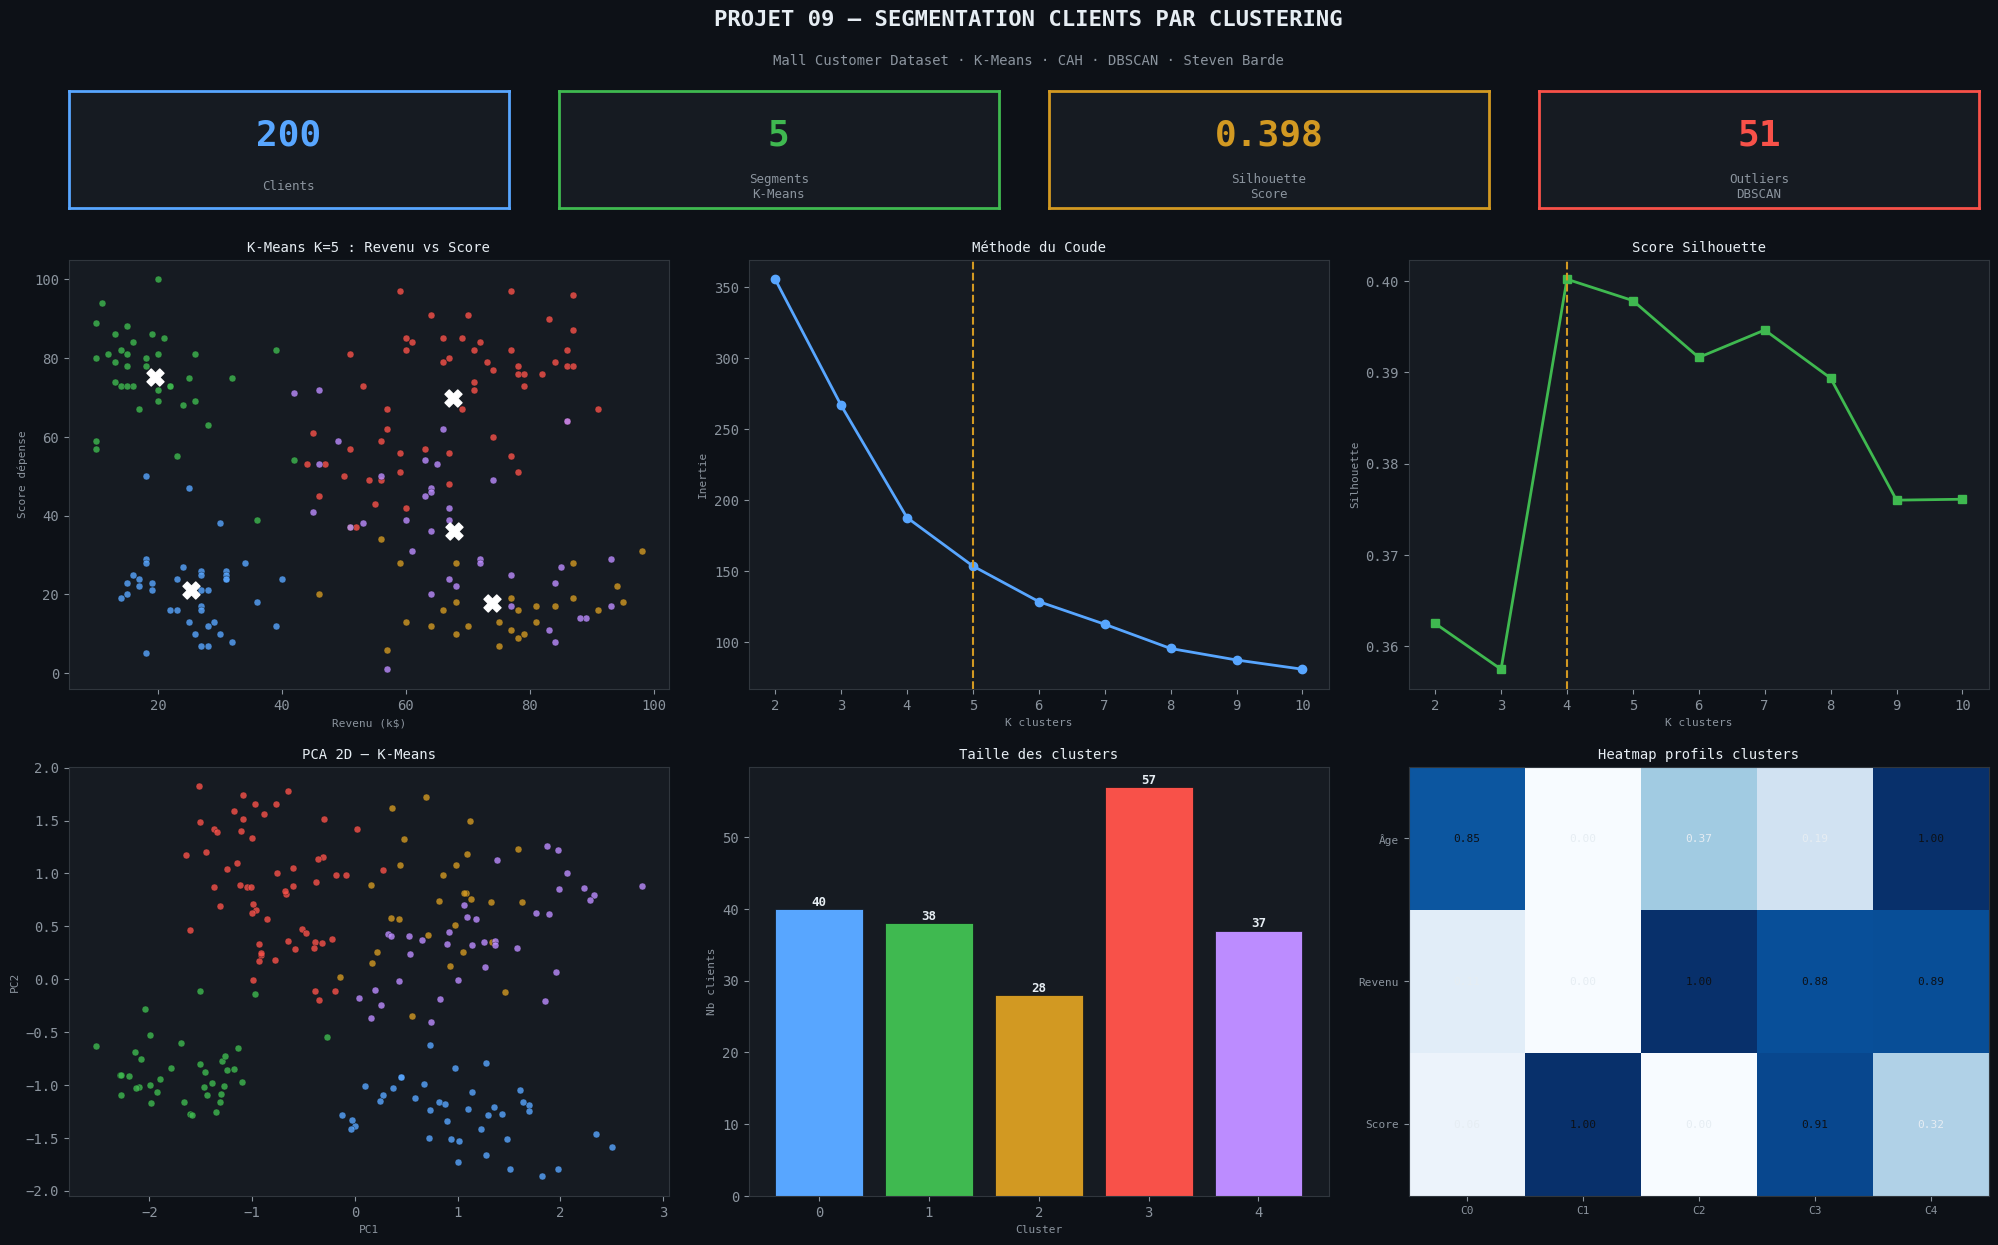

Dashboard principal sauvegardé : ../images/00_dashboard_clustering.png


In [16]:
# ── 16. DASHBOARD FINAL ──────────────────────────────────────────────────────
fig = plt.figure(figsize=(20, 13))
fig.patch.set_facecolor(DARK)

# Titre
fig.text(0.5, 0.97, 'PROJET 09 — SEGMENTATION CLIENTS PAR CLUSTERING',
         ha='center', color=TEXT, fontsize=16, fontweight='bold')
fig.text(0.5, 0.94, 'Mall Customer Dataset · K-Means · CAH · DBSCAN · Steven Barde',
         ha='center', color=DIM, fontsize=10)

# ─── KPI TILES ───────────────────────────────────────────────────────────────
kpis = [
    ('200', 'Clients', BLUE),
    ('5', 'Segments\nK-Means', GREEN),
    (f'{sil:.3f}', 'Silhouette\nScore', ORNG),
    (f'{n_noise}', 'Outliers\nDBSCAN', RED),
]
for i, (val, lbl, clr) in enumerate(kpis):
    x0 = 0.02 + i * 0.245
    ax_kpi = fig.add_axes([x0, 0.83, 0.22, 0.09])
    ax_kpi.set_facecolor(CARD)
    for spine in ax_kpi.spines.values(): spine.set_color(clr); spine.set_linewidth(2)
    ax_kpi.set_xticks([]); ax_kpi.set_yticks([])
    ax_kpi.text(0.5, 0.62, val,  ha='center', va='center', color=clr,  fontsize=26, fontweight='bold', transform=ax_kpi.transAxes)
    ax_kpi.text(0.5, 0.18, lbl,  ha='center', va='center', color=DIM,  fontsize=9,  transform=ax_kpi.transAxes)

# ─── CHARTS ──────────────────────────────────────────────────────────────────
# [0,0] K-Means scatter Income vs Score
ax1 = fig.add_axes([0.02, 0.46, 0.30, 0.33])
ax1.set_facecolor(CARD)
for i, (clust, grp) in enumerate(df.groupby('Cluster_KMeans')):
    ax1.scatter(grp['Annual_Income_k'], grp['Spending_Score'],
                c=CLUSTER_COLORS[i], s=25, alpha=0.8, edgecolors=DARK, linewidths=0.3)
ax1.scatter(centroids_real['Annual_Income_k'], centroids_real['Spending_Score'],
            c='white', s=150, marker='X', zorder=5)
ax1.set_title('K-Means K=5 : Revenu vs Score', color=TEXT, fontsize=10)
ax1.set_xlabel('Revenu (k$)', color=DIM, fontsize=8)
ax1.set_ylabel('Score dépense', color=DIM, fontsize=8)
for spine in ax1.spines.values(): spine.set_color(BORD)

# [0,1] Méthode du coude
ax2 = fig.add_axes([0.36, 0.46, 0.29, 0.33])
ax2.set_facecolor(CARD)
ax2.plot(list(K_range), inertias, 'o-', color=BLUE, linewidth=2, markersize=6)
ax2.axvline(x=5, color=ORNG, linestyle='--', linewidth=1.5)
ax2.set_title('Méthode du Coude', color=TEXT, fontsize=10)
ax2.set_xlabel('K clusters', color=DIM, fontsize=8)
ax2.set_ylabel('Inertie', color=DIM, fontsize=8)
for spine in ax2.spines.values(): spine.set_color(BORD)

# [0,2] Silhouette
ax3 = fig.add_axes([0.69, 0.46, 0.29, 0.33])
ax3.set_facecolor(CARD)
ax3.plot(list(K_range), silhouettes, 's-', color=GREEN, linewidth=2, markersize=6)
ax3.axvline(x=best_k, color=ORNG, linestyle='--', linewidth=1.5)
ax3.set_title('Score Silhouette', color=TEXT, fontsize=10)
ax3.set_xlabel('K clusters', color=DIM, fontsize=8)
ax3.set_ylabel('Silhouette', color=DIM, fontsize=8)
for spine in ax3.spines.values(): spine.set_color(BORD)

# [1,0] PCA K-Means
ax4 = fig.add_axes([0.02, 0.07, 0.30, 0.33])
ax4.set_facecolor(CARD)
for i, (clust, grp) in enumerate(df.groupby('Cluster_KMeans')):
    mask = df['Cluster_KMeans'] == clust
    ax4.scatter(X_pca[mask, 0], X_pca[mask, 1], c=CLUSTER_COLORS[i], s=25, alpha=0.8, edgecolors=DARK, linewidths=0.3)
ax4.set_title('PCA 2D — K-Means', color=TEXT, fontsize=10)
ax4.set_xlabel('PC1', color=DIM, fontsize=8); ax4.set_ylabel('PC2', color=DIM, fontsize=8)
for spine in ax4.spines.values(): spine.set_color(BORD)

# [1,1] Taille des clusters (barres)
ax5 = fig.add_axes([0.36, 0.07, 0.29, 0.33])
ax5.set_facecolor(CARD)
sizes = df.groupby('Cluster_KMeans').size()
bars = ax5.bar(sizes.index, sizes.values, color=CLUSTER_COLORS[:5], edgecolor=DARK, linewidth=0.5)
for bar, v in zip(bars, sizes.values):
    ax5.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5, str(v),
             ha='center', color=TEXT, fontsize=9, fontweight='bold')
ax5.set_title('Taille des clusters', color=TEXT, fontsize=10)
ax5.set_xlabel('Cluster', color=DIM, fontsize=8)
ax5.set_ylabel('Nb clients', color=DIM, fontsize=8)
for spine in ax5.spines.values(): spine.set_color(BORD)

# [1,2] Profil radar / heatmap comparaison
ax6 = fig.add_axes([0.69, 0.07, 0.29, 0.33])
ax6.set_facecolor(CARD)
profile_norm = centroids_real[features].copy()
for col in features:
    profile_norm[col] = (profile_norm[col] - profile_norm[col].min()) / (profile_norm[col].max() - profile_norm[col].min())
im = ax6.imshow(profile_norm.values.T, aspect='auto', cmap='Blues', vmin=0, vmax=1)
ax6.set_xticks(range(K_OPTIMAL))
ax6.set_xticklabels([f'C{i}' for i in range(K_OPTIMAL)], color=DIM, fontsize=8)
ax6.set_yticks(range(len(features)))
ax6.set_yticklabels(['Âge', 'Revenu', 'Score'], color=DIM, fontsize=8)
ax6.set_title('Heatmap profils clusters', color=TEXT, fontsize=10)
for spine in ax6.spines.values(): spine.set_color(BORD)
# Annotations
for i in range(K_OPTIMAL):
    for j in range(len(features)):
        ax6.text(i, j, f'{profile_norm.values[i, j]:.2f}', ha='center', va='center',
                 color=TEXT if profile_norm.values[i, j] < 0.7 else DARK, fontsize=8)

plt.savefig('../images/00_dashboard_clustering.png', dpi=130, bbox_inches='tight', facecolor=DARK)
plt.show()
print('Dashboard principal sauvegardé : ../images/00_dashboard_clustering.png')

In [17]:
# ── 17. SYNTHÈSE ─────────────────────────────────────────────────────────────
print('\n' + '='*55)
print('       SYNTHÈSE — PROJET 09 CLUSTERING')
print('='*55)
print(f'Dataset        : Mall Customer Segmentation')
print(f'Clients        : {len(df)}')
print(f'Variables      : Age, Revenu annuel, Score de dépense')
print()
print('Algorithmes testés :')
print(f'  K-Means      → K=5 clusters, silhouette={sil:.3f}')
print(f'  CAH (Ward)   → K=5 clusters, silhouette={sil_cah:.3f}')
print(f'  DBSCAN       → {n_clusters_db} clusters, {n_noise} outliers')
print()
print('Segments identifiés (K-Means) :')
for _, row in centroids_real.iterrows():
    print(f'  {row["Segment"]:28s} | {int(row["Taille"]):3d} clients ({row["% Total"]}%)')
print()
print('Images générées :')
for img in ['01_eda','02_elbow_silhouette','03_kmeans_2d','04_kmeans_3d',
            '05_dendrogram','06_cah_clusters','07_dbscan','08_pca_comparison',
            '00_dashboard_clustering']:
    print(f'  ../images/{img}.png')
print('='*55)


       SYNTHÈSE — PROJET 09 CLUSTERING
Dataset        : Mall Customer Segmentation
Clients        : 200
Variables      : Age, Revenu annuel, Score de dépense

Algorithmes testés :
  K-Means      → K=5 clusters, silhouette=0.398
  CAH (Ward)   → K=5 clusters, silhouette=0.358
  DBSCAN       → 8 clusters, 51 outliers

Segments identifiés (K-Means) :
  ⚖️ Clients Prudents          |  40 clients (20.0%)
  🛍️ Dépensiers Modestes       |  38 clients (19.0%)
  💼 Riches Économes            |  28 clients (14.0%)
  💎 Clients Premium            |  57 clients (28.5%)
  💼 Riches Économes            |  37 clients (18.5%)

Images générées :
  ../images/01_eda.png
  ../images/02_elbow_silhouette.png
  ../images/03_kmeans_2d.png
  ../images/04_kmeans_3d.png
  ../images/05_dendrogram.png
  ../images/06_cah_clusters.png
  ../images/07_dbscan.png
  ../images/08_pca_comparison.png
  ../images/00_dashboard_clustering.png
